⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest ATR Volatility Bidirectional Strategy (WITH FEE)...

METRICS (ATR Volatility Bidirectional Breakout) - WITH FEE
     Final Equity: 27300.1277
     Total Return: 1.7300
    CAGR (approx): 0.5957
     Max Drawdown: -0.2561
           Sharpe: 1.4301
           Trades: 406
          Winrate: 0.4015
    Avg PnL/Trade: 40.2388
    Profit Factor: 1.2718
           Max DD: -0.256084467335


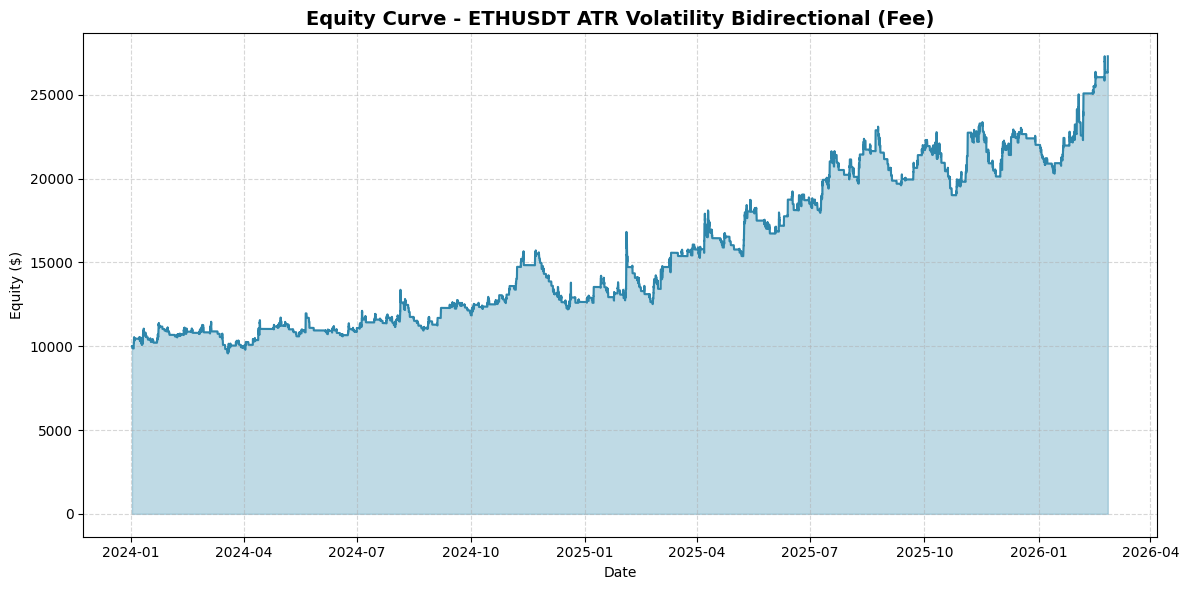


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit   Gross PnL  Entry Fee  Exit Fee         PnL       Reason       Capital  Bars Held
0 2024-01-02 10:00:00   LONG  2421.585391  2394.029000 -113.794832   4.000000  3.954482 -121.749315    Stop Loss   9878.250685          2
1 2024-01-03 12:00:00  SHORT  2314.868474  2230.740793  358.998505   3.951300  3.807701  351.239504  Take Profit  10229.490189          1
2 2024-01-04 08:00:00  SHORT  2267.159626  2215.950000  231.059324   4.091796  3.999372  222.968155    Time Exit  10452.458345         18
3 2024-01-08 07:00:00  SHORT  2205.439127  2228.152740 -107.648896   4.180983  4.224043 -116.053922    Stop Loss  10336.404422          8
4 2024-01-09 12:00:00   LONG  2312.576448  2279.202542 -149.169640   4.134562  4.074894 -157.379095    Stop Loss  10179.025327         18
5 2024-01-10 18:00:00   LONG  2370.925218  2435.040000  275.262155   4.071610  4.181715  267.008830    Time Exit  10446.034157         18
6 202

C:\Users\User\AppData\Local\Temp\ipykernel_9176\896941996.py:427: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby("Type", sort=False).apply(_calc)


In [3]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) HÀM TÍNH CHỈ BÁO
# =========================================================
def calculate_indicators(df):
    data = df.copy()

    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)

    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_25'] = calc_atr(data['TR'], 25)
    data['ATR_30'] = calc_atr(data['TR'], 30)

    data['Highest_Close_20'] = data['Close'].rolling(window=20).max()
    data['Lowest_Close_20'] = data['Close'].rolling(window=20).min()

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER (CÓ FEE)
# =========================================================
class ATRVolatilityBidirectionalBacktester:
    def __init__(self, df, initial_capital=10000, fee_rate=0.0004):
        self.df = df
        self.initial_capital = initial_capital
        self.capital = float(initial_capital)
        self.equity_curve = []
        self.trades = []

        # Fee per side (ví dụ 0.0004 = 0.04% mỗi chiều)
        self.fee_rate = float(fee_rate)

        # Position state
        self.position = 0  # 0=flat, 1=long, -1=short
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.bars_held = 0

        # Notional base tại entry (capital trước khi trừ fee)
        self.trade_capital = 0.0
        self.entry_fee_paid = 0.0

        # Pending orders
        self.pending_long = None
        self.pending_short = None

        # Strategy Parameters
        self.lookback = 20
        self.entry_factor = 2.4
        self.sl_factor = 1.6
        self.tp_factor = 4.4
        self.order_expiry_bars = 8
        self.time_exit_bars = 18

    def run(self):
        indices = self.df.index

        for i in range(4, len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # A) QUẢN LÝ VỊ THẾ ĐANG MỞ
            if self.position != 0:
                self.bars_held += 1

                exit_happened = False
                exit_price = 0.0
                exit_reason = ""

                if self.position == 1:  # Long
                    if current_bar['Low'] <= self.sl:
                        exit_price = self.sl
                        exit_reason = "Stop Loss"
                        exit_happened = True
                    elif current_bar['High'] >= self.tp:
                        exit_price = self.tp
                        exit_reason = "Take Profit"
                        exit_happened = True
                    elif self.bars_held >= self.time_exit_bars:
                        exit_price = float(current_bar['Close'])
                        exit_reason = "Time Exit"
                        exit_happened = True

                elif self.position == -1:  # Short
                    if current_bar['High'] >= self.sl:
                        exit_price = self.sl
                        exit_reason = "Stop Loss"
                        exit_happened = True
                    elif current_bar['Low'] <= self.tp:
                        exit_price = self.tp
                        exit_reason = "Take Profit"
                        exit_happened = True
                    elif self.bars_held >= self.time_exit_bars:
                        exit_price = float(current_bar['Close'])
                        exit_reason = "Time Exit"
                        exit_happened = True

                if exit_happened:
                    self.close_position(exit_price, idx, exit_reason)
                    self.equity_curve.append({'time': idx, 'equity': self.capital})
                    continue

            # B) QUẢN LÝ PENDING ORDERS
            if self.position == 0:
                # Pending long
                if self.pending_long is not None:
                    bars_since_creation = i - self.pending_long['created_idx']
                    if bars_since_creation <= self.order_expiry_bars:
                        if current_bar['High'] >= self.pending_long['price']:
                            self.open_position(1, float(self.pending_long['price']), i, idx)
                            self.pending_long = None
                            self.pending_short = None
                            self.equity_curve.append({'time': idx, 'equity': self.capital})
                            continue
                    else:
                        self.pending_long = None

                # Pending short
                if self.pending_short is not None:
                    bars_since_creation = i - self.pending_short['created_idx']
                    if bars_since_creation <= self.order_expiry_bars:
                        if current_bar['Low'] <= self.pending_short['price']:
                            self.open_position(-1, float(self.pending_short['price']), i, idx)
                            self.pending_short = None
                            self.pending_long = None
                            self.equity_curve.append({'time': idx, 'equity': self.capital})
                            continue
                    else:
                        self.pending_short = None

                # C) SCAN CƠ HỘI MỚI (tạo pending)
                if self.pending_long is None and self.pending_short is None:
                    if i >= 3:
                        atr30_prev2 = float(self.df.iloc[i-2]['ATR_30'])
                        atr30_prev3 = float(self.df.iloc[i-3]['ATR_30'])

                        if atr30_prev2 > atr30_prev3:
                            ref_atr = float(self.df.iloc[i-3]['ATR_20'])
                            highest_close = float(self.df.iloc[i-2]['Highest_Close_20'])
                            lowest_close = float(self.df.iloc[i-2]['Lowest_Close_20'])

                            long_trigger = highest_close + (self.entry_factor * ref_atr)
                            short_trigger = lowest_close - (self.entry_factor * ref_atr)

                            self.pending_long = {'price': long_trigger, 'created_idx': i}
                            self.pending_short = {'price': short_trigger, 'created_idx': i}

            # D) APPEND EQUITY
            self.append_equity(idx)

    def append_equity(self, idx):
        """
        Equity = capital (đã trừ fee đã phát sinh) + gross unrealized PnL
        gross unrealized PnL tính theo trade_capital (notional base lúc entry)
        """
        if self.position == 0:
            self.equity_curve.append({'time': idx, 'equity': self.capital})
        else:
            current_price = float(self.df.loc[idx, 'Close'])
            base = float(self.trade_capital) if self.trade_capital > 0 else float(self.capital)

            if self.position == 1:
                unrealized_pnl = ((current_price - self.entry_price) / self.entry_price) * base
            else:
                unrealized_pnl = ((self.entry_price - current_price) / self.entry_price) * base

            self.equity_curve.append({'time': idx, 'equity': self.capital + unrealized_pnl})

    def open_position(self, pos_type, price, bar_idx, time_idx):
        """
        Vào lệnh:
        - trade_capital = capital tại entry (trước fee)
        - trừ entry fee ngay lập tức: fee_rate * trade_capital
        """
        self.position = int(pos_type)
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)
        self.bars_held = 0

        self.trade_capital = float(self.capital)  # notional base
        self.entry_fee_paid = self.fee_rate * self.trade_capital
        self.capital -= self.entry_fee_paid

        atr_20 = float(self.df.iloc[bar_idx]['ATR_20'])
        atr_25 = float(self.df.iloc[bar_idx]['ATR_25'])

        if self.position == 1:
            self.sl = self.entry_price - (self.sl_factor * atr_20)
            self.tp = self.entry_price + (self.tp_factor * atr_25)
        else:
            self.sl = self.entry_price + (self.sl_factor * atr_20)
            self.tp = self.entry_price - (self.tp_factor * atr_25)

    def close_position(self, exit_price, time_idx, reason):
        """
        Thoát lệnh:
        - gross_pnl tính theo trade_capital (notional base lúc entry)
        - trừ exit fee theo notional tại exit ~ trade_capital * (exit/entry)
        - lưu PnL = NET (gross - entry_fee - exit_fee) để metrics phản ánh fee
        """
        exit_price = float(exit_price)
        base = float(self.trade_capital) if self.trade_capital > 0 else float(self.capital)

        if self.position == 1:
            gross_pnl = ((exit_price - self.entry_price) / self.entry_price) * base
            pos_type_str = "LONG"
            exit_notional = base * (exit_price / self.entry_price)
        else:
            gross_pnl = ((self.entry_price - exit_price) / self.entry_price) * base
            pos_type_str = "SHORT"
            exit_notional = base * (exit_price / self.entry_price)

        exit_fee = self.fee_rate * abs(exit_notional)

        # capital hiện tại đã trừ entry fee -> cộng gross_pnl rồi trừ exit_fee
        self.capital += gross_pnl
        self.capital -= exit_fee

        net_pnl = gross_pnl - self.entry_fee_paid - exit_fee

        self.trades.append({
            "Exit Time": time_idx,
            "Type": pos_type_str,
            "Entry": self.entry_price,
            "Exit": exit_price,
            "Gross PnL": gross_pnl,
            "Entry Fee": self.entry_fee_paid,
            "Exit Fee": exit_fee,
            "PnL": net_pnl,     # NET PnL
            "Reason": reason,
            "Capital": self.capital,
            "Bars Held": self.bars_held
        })

        # Reset
        self.position = 0
        self.bars_held = 0
        self.trade_capital = 0.0
        self.entry_fee_paid = 0.0

# =========================================================
# 4) METRICS
# =========================================================
def calculate_advanced_metrics(trades_df, equity_data, initial_capital):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]

    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_capital) / initial_capital

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_capital) ** (1/years)) - 1 if years > 0 else 0

    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0

    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (ATR Volatility Bidirectional Breakout) - WITH FEE")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print(f"           Max DD: {metrics['Max Drawdown']:.12f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    plt.title(f"Equity Curve - {symbol} ATR Volatility Bidirectional (Fee)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) METRICS THEO LONG/SHORT (GIỐNG ẢNH)
# =========================================================
def side_metrics_table(trades_df: pd.DataFrame) -> pd.DataFrame:
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=[
            "Total_Trades","Wins","Losses","Win_Rate","Avg_PnL","Gross_Profit","Gross_Loss","Profit_Factor"
        ])

    df = trades_df.copy()
    df["Type"] = df["Type"].astype(str).str.upper().str.strip()
    df["PnL"] = pd.to_numeric(df["PnL"], errors="coerce")
    df = df.dropna(subset=["Type", "PnL"])
    df = df[df["Type"].isin(["LONG", "SHORT"])]

    def _calc(g: pd.DataFrame) -> pd.Series:
        total = len(g)
        wins = int((g["PnL"] > 0).sum())
        losses = int((g["PnL"] < 0).sum())
        win_rate = (wins / total * 100.0) if total > 0 else 0.0
        avg_pnl = g["PnL"].mean() if total > 0 else 0.0
        gross_profit = g.loc[g["PnL"] > 0, "PnL"].sum()
        gross_loss = abs(g.loc[g["PnL"] < 0, "PnL"].sum())
        profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else np.inf

        return pd.Series({
            "Total_Trades": total,
            "Wins": wins,
            "Losses": losses,
            "Win_Rate": win_rate,     # %
            "Avg_PnL": avg_pnl,
            "Gross_Profit": gross_profit,
            "Gross_Loss": gross_loss,
            "Profit_Factor": profit_factor
        })

    out = df.groupby("Type", sort=False).apply(_calc)
    out["Win_Rate"] = out["Win_Rate"].astype(float).round(4)
    out["Avg_PnL"] = out["Avg_PnL"].astype(float).round(4)
    out["Gross_Profit"] = out["Gross_Profit"].astype(float).round(4)
    out["Gross_Loss"] = out["Gross_Loss"].astype(float).round(4)
    out["Profit_Factor"] = out["Profit_Factor"].astype(float).replace([np.inf], np.nan).round(4)
    return out

# =========================================================
# 6) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/2/2026"

    # Fee per side: 0.0004 = 0.04%/side (round-trip ~ 0.08%)
    fee_rate = 0.0004

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Đang chạy Backtest ATR Volatility Bidirectional Strategy (WITH FEE)...")
        bt = ATRVolatilityBidirectionalBacktester(df_calc, initial_capital=10000, fee_rate=fee_rate)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_capital)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())

            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())

            print("\n📊 Long vs Short Distribution:")
            print(trades_df['Type'].value_counts())

            print("\n📊 Winrate theo từng phía (Long/Short):")
            print(side_metrics_table(trades_df).to_string())

            print("\n📊 Average Bars Held:")
            print(f"Mean: {trades_df['Bars Held'].mean():.2f}")
            print(f"Median: {trades_df['Bars Held'].median():.2f}")
            print(f"Max: {trades_df['Bars Held'].max()}")
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

In [4]:
# Win/Loss flag
trades_df["Win"] = trades_df["PnL"] > 0

# Thống kê theo Long/Short
side_stats = trades_df.groupby("Type").agg(
    Total_Trades=("PnL", "count"),
    Wins=("Win", "sum"),
    Losses=("Win", lambda x: (~x).sum()),
    Win_Rate=("Win", "mean"),
    Avg_PnL=("PnL", "mean"),
    Gross_Profit=("PnL", lambda x: x[x > 0].sum()),
    Gross_Loss=("PnL", lambda x: abs(x[x < 0].sum()))
)

# Profit Factor theo từng side
side_stats["Profit_Factor"] = side_stats["Gross_Profit"] / side_stats["Gross_Loss"].replace(0, np.nan)

# Đổi Win_Rate sang %
side_stats["Win_Rate"] = side_stats["Win_Rate"] * 100

print("\n📊 Winrate theo từng phía (Long/Short):")
print(side_stats.round(4).to_string())


📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate  Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                         
LONG            188    77     111   40.9574  44.2314    31317.6781  23002.1703         1.3615
SHORT           218    86     132   39.4495  36.7956    45130.3743  37108.9319         1.2162


⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest (V1 + Trend Filter + Vol Filter + Fee)...

METRICS (V1 + EMA200 trend filter + VOL filter + FEE)
     Final Equity: 35857.5685
     Total Return: 2.5858
    CAGR (approx): 0.8143
     Max Drawdown: -0.1980
           Sharpe: 2.1907
           Trades: 190
          Winrate: 0.4789
    Avg PnL/Trade: 129.4516
    Profit Factor: 1.6084


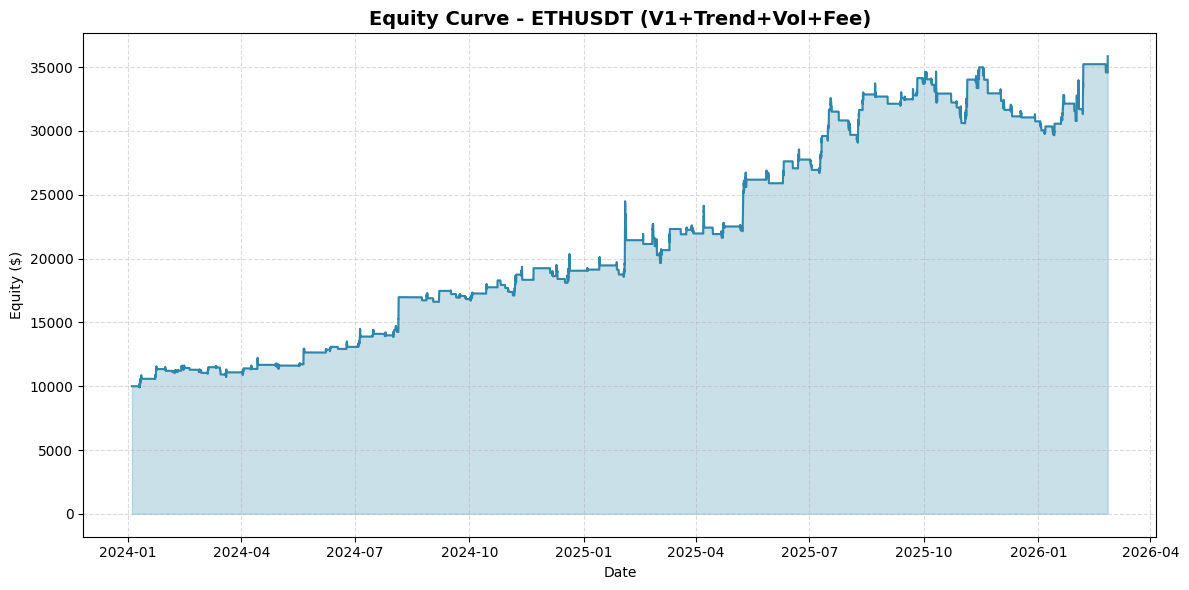


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit   Gross PnL  Entry Fee  Exit Fee         PnL       Reason       Capital  Bars Held
0 2024-01-10 18:00:00   LONG  2367.960440  2435.040000  283.279899   5.000000  5.141640  273.138259    Time Exit  10273.138259         18
1 2024-01-11 15:00:00   LONG  2534.064096  2613.190000  320.777738   5.136569  5.296958  310.344211    Time Exit  10583.482471         18
2 2024-01-22 19:00:00  SHORT  2386.760938  2326.406885  267.624650   5.291741  5.157929  257.174979  Take Profit  10840.657450         10
3 2024-01-23 09:00:00  SHORT  2322.996647  2232.760880  421.100493   5.420329  5.209778  410.470386  Take Profit  11251.127836         11
4 2024-01-24 05:00:00  SHORT  2248.541295  2227.410000  105.735618   5.625564  5.572696   94.537358    Time Exit  11345.665195         18
5 2024-01-31 09:00:00   LONG  2348.995664  2322.637228 -127.311426   5.672833  5.609177 -138.593435    Stop Loss  11207.071759         17
6 202

C:\Users\User\AppData\Local\Temp\ipykernel_9176\2738549758.py:479: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby("Type", sort=False).apply(_calc)


In [7]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS (V1 + EMA200 + VOL FILTER STATS)
# =========================================================
def calculate_indicators(df, lookback=20, ema_len=200, vol_median_win=50):
    data = df.copy()

    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)

    # ATR (EWMA)
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_25'] = calc_atr(data['TR'], 25)
    data['ATR_30'] = calc_atr(data['TR'], 30)

    # Highest/Lowest Close (giữ nguyên V1)
    data[f'Highest_Close_{lookback}'] = data['Close'].rolling(window=lookback).max()
    data[f'Lowest_Close_{lookback}'] = data['Close'].rolling(window=lookback).min()

    # Trend filter EMA200
    data[f'EMA_{ema_len}'] = data['Close'].ewm(span=ema_len, adjust=False).mean()

    # Vol filter stats
    data[f'ATR30_MED_{vol_median_win}'] = data['ATR_30'].rolling(vol_median_win).median()
    data['ATR20_PCT'] = data['ATR_20'] / data['Close']

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER (V1 + TREND FILTER + VOL FILTER + FEE)
# - Giữ nguyên logic pending / SL/TP / time-exit / all-in
# - Thêm:
#   (1) Trend filter EMA200: chỉ đặt 1 phía theo trend
#   (2) Vol filter mạnh hơn: ATR30 rising + ATR30 > median(50) (+ optional ATR20_PCT)
#   (3) Fee per side: trừ fee lúc vào + lúc ra
# =========================================================
class ATRVolatilityBidirectionalBacktester:
    def __init__(self, df, initial_capital=10000, fee_rate=0.0004):
        self.df = df
        self.initial_capital = float(initial_capital)
        self.capital = float(initial_capital)
        self.equity_curve = []
        self.trades = []

        # Fee per side (vd 0.0004 = 0.04% / side)
        self.fee_rate = float(fee_rate)

        # Position state
        self.position = 0  # 0=flat, 1=long, -1=short
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.bars_held = 0

        # Notional base tại entry (capital trước fee)
        self.trade_capital = 0.0
        self.entry_fee_paid = 0.0

        # Pending orders
        self.pending_long = None
        self.pending_short = None

        # Strategy Parameters (giữ V1)
        self.lookback = 20
        self.entry_factor = 2.4
        self.sl_factor = 1.6
        self.tp_factor = 4.4
        self.order_expiry_bars = 8
        self.time_exit_bars = 18

        # === NEW FILTER PARAMS ===
        self.use_trend_filter = True
        self.ema_len = 200
        self.ema_col = f"EMA_{self.ema_len}"

        self.use_vol_median_filter = True
        self.vol_median_win = 50
        self.atr30_med_col = f"ATR30_MED_{self.vol_median_win}"

        self.use_atr_pct_filter = False     # bật nếu muốn giảm trade mạnh hơn
        self.min_atr20_pct = 0.0            # ví dụ 0.004 ~ 0.6 tùy coin/TF

    def run(self):
        indices = self.df.index

        for i in range(4, len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # A) QUẢN LÝ VỊ THẾ ĐANG MỞ
            if self.position != 0:
                self.bars_held += 1

                exit_happened = False
                exit_price = 0.0
                exit_reason = ""

                if self.position == 1:  # Long
                    if current_bar['Low'] <= self.sl:
                        exit_price = self.sl
                        exit_reason = "Stop Loss"
                        exit_happened = True
                    elif current_bar['High'] >= self.tp:
                        exit_price = self.tp
                        exit_reason = "Take Profit"
                        exit_happened = True
                    elif self.bars_held >= self.time_exit_bars:
                        exit_price = float(current_bar['Close'])
                        exit_reason = "Time Exit"
                        exit_happened = True

                elif self.position == -1:  # Short
                    if current_bar['High'] >= self.sl:
                        exit_price = self.sl
                        exit_reason = "Stop Loss"
                        exit_happened = True
                    elif current_bar['Low'] <= self.tp:
                        exit_price = self.tp
                        exit_reason = "Take Profit"
                        exit_happened = True
                    elif self.bars_held >= self.time_exit_bars:
                        exit_price = float(current_bar['Close'])
                        exit_reason = "Time Exit"
                        exit_happened = True

                if exit_happened:
                    self.close_position(exit_price, idx, exit_reason)
                    self.equity_curve.append({'time': idx, 'equity': self.capital})
                    continue

            # B) QUẢN LÝ PENDING ORDERS (khi flat)
            if self.position == 0:
                # Pending long
                if self.pending_long is not None:
                    bars_since_creation = i - self.pending_long['created_idx']
                    if bars_since_creation <= self.order_expiry_bars:
                        if current_bar['High'] >= self.pending_long['price']:
                            self.open_position(1, float(self.pending_long['price']), i, idx)
                            self.pending_long = None
                            self.pending_short = None
                            self.equity_curve.append({'time': idx, 'equity': self.capital})
                            continue
                    else:
                        self.pending_long = None

                # Pending short
                if self.pending_short is not None:
                    bars_since_creation = i - self.pending_short['created_idx']
                    if bars_since_creation <= self.order_expiry_bars:
                        if current_bar['Low'] <= self.pending_short['price']:
                            self.open_position(-1, float(self.pending_short['price']), i, idx)
                            self.pending_short = None
                            self.pending_long = None
                            self.equity_curve.append({'time': idx, 'equity': self.capital})
                            continue
                    else:
                        self.pending_short = None

                # C) SCAN CƠ HỘI MỚI (tạo pending) - V1 + trend/vol filter
                if self.pending_long is None and self.pending_short is None:
                    if i >= 3:
                        # --- VOL FILTER ---
                        atr30_prev2 = float(self.df.iloc[i-2]['ATR_30'])
                        atr30_prev3 = float(self.df.iloc[i-3]['ATR_30'])
                        vol_ok = (atr30_prev2 > atr30_prev3)  # rising

                        if self.use_vol_median_filter:
                            atr30_med = float(self.df.iloc[i-2][self.atr30_med_col])
                            vol_ok = vol_ok and (atr30_prev2 > atr30_med)

                        if self.use_atr_pct_filter:
                            atr20_pct = float(self.df.iloc[i-2]['ATR20_PCT'])
                            vol_ok = vol_ok and (atr20_pct >= self.min_atr20_pct)

                        if not vol_ok:
                            self.append_equity(idx)
                            continue

                        # --- BUILD TRIGGERS (V1 giữ nguyên) ---
                        ref_atr = float(self.df.iloc[i-3]['ATR_20'])
                        highest_close = float(self.df.iloc[i-2][f'Highest_Close_{self.lookback}'])
                        lowest_close  = float(self.df.iloc[i-2][f'Lowest_Close_{self.lookback}'])

                        long_trigger  = highest_close + (self.entry_factor * ref_atr)
                        short_trigger = lowest_close  - (self.entry_factor * ref_atr)

                        # --- TREND FILTER EMA200: chỉ đặt 1 phía theo trend ---
                        if self.use_trend_filter:
                            # dùng bar i-1 để tránh lookahead nhẹ
                            ema_val = float(self.df.iloc[i-1][self.ema_col])
                            close_val = float(self.df.iloc[i-1]['Close'])
                            if close_val >= ema_val:
                                self.pending_long = {'price': long_trigger, 'created_idx': i}
                                self.pending_short = None
                            else:
                                self.pending_short = {'price': short_trigger, 'created_idx': i}
                                self.pending_long = None
                        else:
                            self.pending_long = {'price': long_trigger, 'created_idx': i}
                            self.pending_short = {'price': short_trigger, 'created_idx': i}

            # D) APPEND EQUITY
            self.append_equity(idx)

    def append_equity(self, idx):
        """Equity = capital (đã trừ fee) + gross unrealized PnL tính theo trade_capital."""
        if self.position == 0:
            self.equity_curve.append({'time': idx, 'equity': self.capital})
        else:
            current_price = float(self.df.loc[idx, 'Close'])
            base = float(self.trade_capital) if self.trade_capital > 0 else float(self.capital)

            if self.position == 1:
                unreal = ((current_price - self.entry_price) / self.entry_price) * base
            else:
                unreal = ((self.entry_price - current_price) / self.entry_price) * base

            self.equity_curve.append({'time': idx, 'equity': self.capital + unreal})

    def open_position(self, pos_type, price, bar_idx, time_idx):
        """
        Vào lệnh:
        - trade_capital = capital tại entry (trước fee)
        - trừ entry fee ngay lập tức: fee_rate * notional_entry (xấp xỉ trade_capital)
        """
        self.position = int(pos_type)
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)
        self.bars_held = 0

        # Notional base tại entry
        self.trade_capital = float(self.capital)

        # Pay entry fee (xấp xỉ notional = trade_capital)
        self.entry_fee_paid = self.fee_rate * self.trade_capital
        self.capital -= self.entry_fee_paid

        # ATR at entry bar
        atr_20 = float(self.df.iloc[bar_idx]['ATR_20'])
        atr_25 = float(self.df.iloc[bar_idx]['ATR_25'])

        if self.position == 1:
            self.sl = self.entry_price - (self.sl_factor * atr_20)
            self.tp = self.entry_price + (self.tp_factor * atr_25)
        else:
            self.sl = self.entry_price + (self.sl_factor * atr_20)
            self.tp = self.entry_price - (self.tp_factor * atr_25)

    def close_position(self, exit_price, time_idx, reason):
        """
        Thoát lệnh:
        - gross_pnl tính theo trade_capital (notional base lúc entry)
        - trừ exit fee theo notional tại exit ~ trade_capital * (exit/entry)
        - lưu PnL = NET để metrics phản ánh fee
        """
        exit_price = float(exit_price)
        base = float(self.trade_capital) if self.trade_capital > 0 else float(self.capital)

        if self.position == 1:
            gross_pnl = ((exit_price - self.entry_price) / self.entry_price) * base
            pos_type_str = 'LONG'
            exit_notional = base * (exit_price / self.entry_price)
        else:
            gross_pnl = ((self.entry_price - exit_price) / self.entry_price) * base
            pos_type_str = 'SHORT'
            exit_notional = base * (exit_price / self.entry_price)

        exit_fee = self.fee_rate * abs(exit_notional)

        # capital hiện tại đã trừ entry_fee -> cộng gross rồi trừ exit_fee
        self.capital += gross_pnl
        self.capital -= exit_fee

        net_pnl = gross_pnl - self.entry_fee_paid - exit_fee

        self.trades.append({
            'Exit Time': time_idx,
            'Type': pos_type_str,
            'Entry': self.entry_price,
            'Exit': exit_price,
            'Gross PnL': gross_pnl,
            'Entry Fee': self.entry_fee_paid,
            'Exit Fee': exit_fee,
            'PnL': net_pnl,          # NET PnL
            'Reason': reason,
            'Capital': self.capital,
            'Bars Held': self.bars_held
        })

        # Reset
        self.position = 0
        self.bars_held = 0
        self.trade_capital = 0.0
        self.entry_fee_paid = 0.0

# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_advanced_metrics(trades_df, equity_data, initial_capital):
    eq_df = pd.DataFrame(equity_data).copy()
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]

    final_equity = float(eq_df['equity'].iloc[-1])
    total_return = (final_equity - initial_capital) / initial_capital

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_capital) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df['equity'].cummax()
    dd = (eq_df['equity'] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    wins = int((trades_df['PnL'] > 0).sum()) if total_trades > 0 else 0
    win_rate = wins / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df['PnL'] > 0, 'PnL'].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df['PnL'] < 0, 'PnL'].sum()) if total_trades > 0 else 0.0
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*70)
    print("METRICS (V1 + EMA200 trend filter + VOL filter + FEE)")
    print("="*70)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*70)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.25, color='#2E86AB')
    plt.title(f"Equity Curve - {symbol} (V1+Trend+Vol+Fee)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.45)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) METRICS LONG/SHORT (GIỐNG ẢNH)
# =========================================================
def side_metrics_table(trades_df: pd.DataFrame) -> pd.DataFrame:
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=[
            "Total_Trades","Wins","Losses","Win_Rate","Avg_PnL","Gross_Profit","Gross_Loss","Profit_Factor"
        ])

    df = trades_df.copy()
    df["Type"] = df["Type"].astype(str).str.upper().str.strip()
    df["PnL"] = pd.to_numeric(df["PnL"], errors="coerce")
    df = df.dropna(subset=["Type", "PnL"])
    df = df[df["Type"].isin(["LONG", "SHORT"])]

    def _calc(g: pd.DataFrame) -> pd.Series:
        total = len(g)
        wins = int((g["PnL"] > 0).sum())
        losses = int((g["PnL"] < 0).sum())
        win_rate = (wins / total * 100.0) if total > 0 else 0.0
        avg_pnl = g["PnL"].mean() if total > 0 else 0.0
        gross_profit = g.loc[g["PnL"] > 0, "PnL"].sum()
        gross_loss = abs(g.loc[g["PnL"] < 0, "PnL"].sum())
        profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else np.inf

        return pd.Series({
            "Total_Trades": total,
            "Wins": wins,
            "Losses": losses,
            "Win_Rate": win_rate,
            "Avg_PnL": avg_pnl,
            "Gross_Profit": gross_profit,
            "Gross_Loss": gross_loss,
            "Profit_Factor": profit_factor
        })

    out = df.groupby("Type", sort=False).apply(_calc)
    out["Win_Rate"] = out["Win_Rate"].astype(float).round(4)
    out["Avg_PnL"] = out["Avg_PnL"].astype(float).round(4)
    out["Gross_Profit"] = out["Gross_Profit"].astype(float).round(4)
    out["Gross_Loss"] = out["Gross_Loss"].astype(float).round(4)
    out["Profit_Factor"] = out["Profit_Factor"].astype(float).replace([np.inf], np.nan).round(4)
    return out

# =========================================================
# 6) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/2/2026"

    fee_rate = 0.0005  # 0.04% per side (~0.08% round-trip)

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw, lookback=20, ema_len=200, vol_median_win=50)

        print("🚀 Đang chạy Backtest (V1 + Trend Filter + Vol Filter + Fee)...")
        bt = ATRVolatilityBidirectionalBacktester(df_calc, initial_capital=10000, fee_rate=fee_rate)

        # ====== BẬT/TẮT FILTER Ở ĐÂY ======
        bt.use_trend_filter = True             # EMA200 bias 1 phía
        bt.use_vol_median_filter = True        # ATR30 > median(50)

        bt.use_atr_pct_filter = False          # nếu muốn giảm trade mạnh hơn -> True
        bt.min_atr20_pct = 0.004               # chỉ có hiệu lực khi use_atr_pct_filter=True
        # ==================================

        bt.run()
        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_capital)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())

            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())

            print("\n📊 Long vs Short Distribution:")
            print(trades_df['Type'].value_counts())

            print("\n📊 Winrate theo từng phía (Long/Short):")
            print(side_metrics_table(trades_df).to_string())

            print("\n📊 Average Bars Held:")
            print(f"Mean: {trades_df['Bars Held'].mean():.2f}")
            print(f"Median: {trades_df['Bars Held'].median():.2f}")
            print(f"Max: {trades_df['Bars Held'].max()}")
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

In [8]:
# Win/Loss flag
trades_df["Win"] = trades_df["PnL"] > 0

# Thống kê theo Long/Short
side_stats = trades_df.groupby("Type").agg(
    Total_Trades=("PnL", "count"),
    Wins=("Win", "sum"),
    Losses=("Win", lambda x: (~x).sum()),
    Win_Rate=("Win", "mean"),
    Avg_PnL=("PnL", "mean"),
    Gross_Profit=("PnL", lambda x: x[x > 0].sum()),
    Gross_Loss=("PnL", lambda x: abs(x[x < 0].sum()))
)

# Profit Factor theo từng side
side_stats["Profit_Factor"] = side_stats["Gross_Profit"] / side_stats["Gross_Loss"].replace(0, np.nan)

# Đổi Win_Rate sang %
side_stats["Win_Rate"] = side_stats["Win_Rate"] * 100

print("\n📊 Winrate theo từng phía (Long/Short):")
print(side_stats.round(4).to_string())


📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate   Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                          
LONG             87    43      44   49.4253  137.7720    25134.3297  13148.1621         1.9116
SHORT           103    48      55   46.6019  122.4237    39888.1735  27278.5282         1.4623


⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Running backtest (Split Params Long/Short)...

METRICS (V1 + EMA Trend + Vol Filter + Fee + Split Params Long/Short)
     Final Equity: 34021.0011
     Total Return: 2.4021
    CAGR (approx): 0.7703
     Max Drawdown: -0.1981
           Sharpe: 2.0761
           Trades: 197
          Winrate: 0.4721
    Avg PnL/Trade: 115.5271
    Profit Factor: 1.5504


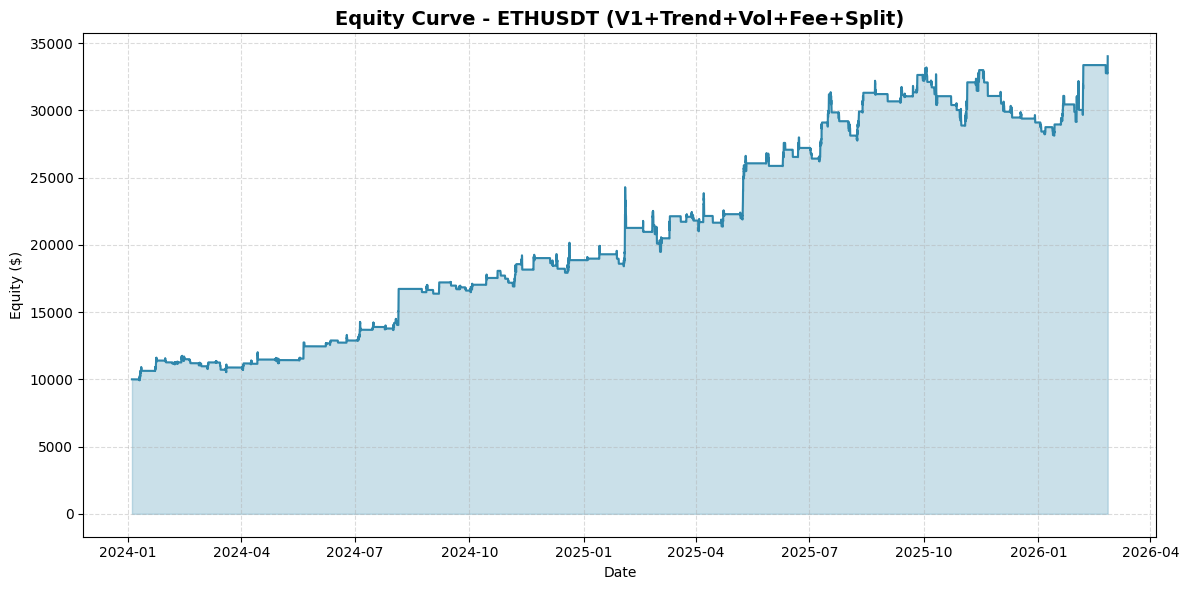


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit   Gross PnL  Entry Fee  Exit Fee         PnL       Reason       Capital  Bars Held
0 2024-01-10 18:00:00   LONG  2363.563737  2435.040000  302.408866   5.000000  5.151204  292.257661    Time Exit  10292.257661         18
1 2024-01-11 15:00:00   LONG  2527.000422  2613.190000  351.042818   5.146129  5.321650  340.575039    Time Exit  10632.832701         18
2 2024-01-22 19:00:00  SHORT  2386.760938  2326.406885  268.872569   5.316416  5.181980  258.374173  Take Profit  10891.206874         10
3 2024-01-23 09:00:00  SHORT  2322.996647  2232.760880  423.064063   5.445603  5.234071  412.384388  Take Profit  11303.591262         11
4 2024-01-24 05:00:00  SHORT  2248.541295  2227.410000  106.228658   5.651796  5.598681   94.978181    Time Exit  11398.569443         18
5 2024-01-31 09:00:00   LONG  2346.398525  2321.494909 -120.979279   5.699285  5.638795 -132.317359    Stop Loss  11266.252084         18
6 202

C:\Users\User\AppData\Local\Temp\ipykernel_9176\282486865.py:483: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby("Type", sort=False).apply(_calc)


In [13]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS (V1 + EMA200 + VOL FILTER STATS)
# =========================================================
def calculate_indicators(df, lookback=20, ema_len=200, vol_median_win=50):
    data = df.copy()

    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)

    # ATR (EWMA)
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_25'] = calc_atr(data['TR'], 25)
    data['ATR_30'] = calc_atr(data['TR'], 30)

    # Highest/Lowest Close (giữ nguyên V1)
    data[f'Highest_Close_{lookback}'] = data['Close'].rolling(window=lookback).max()
    data[f'Lowest_Close_{lookback}'] = data['Close'].rolling(window=lookback).min()

    # Trend filter EMA
    data[f'EMA_{ema_len}'] = data['Close'].ewm(span=ema_len, adjust=False).mean()

    # Vol filter stats
    data[f'ATR30_MED_{vol_median_win}'] = data['ATR_30'].rolling(vol_median_win).median()
    data['ATR20_PCT'] = data['ATR_20'] / data['Close']

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER
# - V1 pending/SL/TP/time-exit/all-in giữ nguyên
# - Thêm: EMA trend filter + vol filter + fee
# - Tách params LONG/SHORT:
#   entry_factor_{long/short}, sl_factor_{long/short}, tp_factor_{long/short},
#   order_expiry_bars_{long/short}, time_exit_bars_{long/short}
# =========================================================
class ATRVolatilityBidirectionalBacktester:
    def __init__(self, df, initial_capital=10000, fee_rate=0.0004):
        self.df = df
        self.initial_capital = float(initial_capital)
        self.capital = float(initial_capital)
        self.equity_curve = []
        self.trades = []

        # Fee per side
        self.fee_rate = float(fee_rate)

        # Position state
        self.position = 0  # 0=flat, 1=long, -1=short
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.bars_held = 0

        # Notional base tại entry (capital trước fee)
        self.trade_capital = 0.0
        self.entry_fee_paid = 0.0

        # Pending orders
        self.pending_long = None
        self.pending_short = None

        # ===== Strategy Params =====
        self.lookback = 20  # dùng chung (khuyến nghị)

        # tách theo LONG/SHORT
        self.entry_factor_long = 2.2
        self.entry_factor_short = 2.4

        self.sl_factor_long = 1.6
        self.tp_factor_long = 4.4

        self.sl_factor_short = 1.6
        self.tp_factor_short = 4.4

        self.order_expiry_bars_long = 8
        self.order_expiry_bars_short = 8

        self.time_exit_bars_long = 18
        self.time_exit_bars_short = 18

        # ===== Filters =====
        self.use_trend_filter = True
        self.ema_len = 200
        self.ema_col = f"EMA_{self.ema_len}"

        self.use_vol_median_filter = True
        self.vol_median_win = 50
        self.atr30_med_col = f"ATR30_MED_{self.vol_median_win}"

        self.use_atr_pct_filter = False     # bật nếu muốn giảm trade mạnh hơn
        self.min_atr20_pct = 0.0            # ví dụ 0.004

    def run(self):
        indices = self.df.index

        for i in range(4, len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # A) QUẢN LÝ VỊ THẾ ĐANG MỞ
            if self.position != 0:
                self.bars_held += 1

                exit_happened = False
                exit_price = 0.0
                exit_reason = ""

                if self.position == 1:  # LONG
                    if current_bar['Low'] <= self.sl:
                        exit_price = self.sl
                        exit_reason = "Stop Loss"
                        exit_happened = True
                    elif current_bar['High'] >= self.tp:
                        exit_price = self.tp
                        exit_reason = "Take Profit"
                        exit_happened = True
                    elif self.bars_held >= self.time_exit_bars_long:
                        exit_price = float(current_bar['Close'])
                        exit_reason = "Time Exit"
                        exit_happened = True

                elif self.position == -1:  # SHORT
                    if current_bar['High'] >= self.sl:
                        exit_price = self.sl
                        exit_reason = "Stop Loss"
                        exit_happened = True
                    elif current_bar['Low'] <= self.tp:
                        exit_price = self.tp
                        exit_reason = "Take Profit"
                        exit_happened = True
                    elif self.bars_held >= self.time_exit_bars_short:
                        exit_price = float(current_bar['Close'])
                        exit_reason = "Time Exit"
                        exit_happened = True

                if exit_happened:
                    self.close_position(exit_price, idx, exit_reason)
                    self.equity_curve.append({'time': idx, 'equity': self.capital})
                    continue

            # B) QUẢN LÝ PENDING ORDERS (khi flat)
            if self.position == 0:
                # Pending LONG
                if self.pending_long is not None:
                    bars_since_creation = i - self.pending_long['created_idx']
                    if bars_since_creation <= self.order_expiry_bars_long:
                        if current_bar['High'] >= self.pending_long['price']:
                            self.open_position(1, float(self.pending_long['price']), i, idx)
                            self.pending_long = None
                            self.pending_short = None
                            self.equity_curve.append({'time': idx, 'equity': self.capital})
                            continue
                    else:
                        self.pending_long = None

                # Pending SHORT
                if self.pending_short is not None:
                    bars_since_creation = i - self.pending_short['created_idx']
                    if bars_since_creation <= self.order_expiry_bars_short:
                        if current_bar['Low'] <= self.pending_short['price']:
                            self.open_position(-1, float(self.pending_short['price']), i, idx)
                            self.pending_short = None
                            self.pending_long = None
                            self.equity_curve.append({'time': idx, 'equity': self.capital})
                            continue
                    else:
                        self.pending_short = None

                # C) SCAN CƠ HỘI MỚI (tạo pending) - V1 + trend/vol filter
                if self.pending_long is None and self.pending_short is None and i >= 3:
                    # --- VOL FILTER ---
                    atr30_prev2 = float(self.df.iloc[i-2]['ATR_30'])
                    atr30_prev3 = float(self.df.iloc[i-3]['ATR_30'])
                    vol_ok = (atr30_prev2 > atr30_prev3)  # rising

                    if self.use_vol_median_filter:
                        atr30_med = float(self.df.iloc[i-2][self.atr30_med_col])
                        vol_ok = vol_ok and (atr30_prev2 > atr30_med)

                    if self.use_atr_pct_filter:
                        atr20_pct = float(self.df.iloc[i-2]['ATR20_PCT'])
                        vol_ok = vol_ok and (atr20_pct >= self.min_atr20_pct)

                    if vol_ok:
                        # --- BUILD TRIGGERS (tách entry factor) ---
                        ref_atr = float(self.df.iloc[i-3]['ATR_20'])
                        highest_close = float(self.df.iloc[i-2][f'Highest_Close_{self.lookback}'])
                        lowest_close  = float(self.df.iloc[i-2][f'Lowest_Close_{self.lookback}'])

                        long_trigger  = highest_close + (self.entry_factor_long  * ref_atr)
                        short_trigger = lowest_close  - (self.entry_factor_short * ref_atr)

                        # --- TREND FILTER EMA: chỉ đặt 1 phía theo trend ---
                        if self.use_trend_filter:
                            ema_val = float(self.df.iloc[i-1][self.ema_col])   # dùng i-1 cho chắc
                            close_val = float(self.df.iloc[i-1]['Close'])
                            if close_val >= ema_val:
                                self.pending_long = {'price': long_trigger, 'created_idx': i}
                                self.pending_short = None
                            else:
                                self.pending_short = {'price': short_trigger, 'created_idx': i}
                                self.pending_long = None
                        else:
                            self.pending_long = {'price': long_trigger, 'created_idx': i}
                            self.pending_short = {'price': short_trigger, 'created_idx': i}

            # D) APPEND EQUITY
            self.append_equity(idx)

    def append_equity(self, idx):
        """Equity = capital (đã trừ fee) + gross unrealized PnL tính theo trade_capital."""
        if self.position == 0:
            self.equity_curve.append({'time': idx, 'equity': self.capital})
        else:
            current_price = float(self.df.loc[idx, 'Close'])
            base = float(self.trade_capital) if self.trade_capital > 0 else float(self.capital)

            if self.position == 1:
                unreal = ((current_price - self.entry_price) / self.entry_price) * base
            else:
                unreal = ((self.entry_price - current_price) / self.entry_price) * base

            self.equity_curve.append({'time': idx, 'equity': self.capital + unreal})

    def open_position(self, pos_type, price, bar_idx, time_idx):
        """
        Vào lệnh (all-in):
        - trade_capital = capital tại entry (trước fee)
        - trừ entry fee: fee_rate * trade_capital
        - SL/TP tách theo LONG/SHORT
        """
        self.position = int(pos_type)
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)
        self.bars_held = 0

        # Notional base tại entry
        self.trade_capital = float(self.capital)

        # Pay entry fee (xấp xỉ notional = trade_capital)
        self.entry_fee_paid = self.fee_rate * self.trade_capital
        self.capital -= self.entry_fee_paid

        atr_20 = float(self.df.iloc[bar_idx]['ATR_20'])
        atr_25 = float(self.df.iloc[bar_idx]['ATR_25'])

        if self.position == 1:  # LONG
            self.sl = self.entry_price - (self.sl_factor_long * atr_20)
            self.tp = self.entry_price + (self.tp_factor_long * atr_25)
        else:  # SHORT
            self.sl = self.entry_price + (self.sl_factor_short * atr_20)
            self.tp = self.entry_price - (self.tp_factor_short * atr_25)

    def close_position(self, exit_price, time_idx, reason):
        """
        Thoát lệnh:
        - gross_pnl tính theo trade_capital (notional base lúc entry)
        - trừ exit fee theo notional tại exit ~ trade_capital * (exit/entry)
        - lưu PnL = NET để metrics phản ánh fee
        """
        exit_price = float(exit_price)
        base = float(self.trade_capital) if self.trade_capital > 0 else float(self.capital)

        if self.position == 1:
            gross_pnl = ((exit_price - self.entry_price) / self.entry_price) * base
            pos_type_str = 'LONG'
            exit_notional = base * (exit_price / self.entry_price)
        else:
            gross_pnl = ((self.entry_price - exit_price) / self.entry_price) * base
            pos_type_str = 'SHORT'
            exit_notional = base * (exit_price / self.entry_price)

        exit_fee = self.fee_rate * abs(exit_notional)

        self.capital += gross_pnl
        self.capital -= exit_fee

        net_pnl = gross_pnl - self.entry_fee_paid - exit_fee

        self.trades.append({
            'Exit Time': time_idx,
            'Type': pos_type_str,
            'Entry': self.entry_price,
            'Exit': exit_price,
            'Gross PnL': gross_pnl,
            'Entry Fee': self.entry_fee_paid,
            'Exit Fee': exit_fee,
            'PnL': net_pnl,
            'Reason': reason,
            'Capital': self.capital,
            'Bars Held': self.bars_held
        })

        # Reset
        self.position = 0
        self.bars_held = 0
        self.trade_capital = 0.0
        self.entry_fee_paid = 0.0

# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_advanced_metrics(trades_df, equity_data, initial_capital):
    eq_df = pd.DataFrame(equity_data).copy()
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]

    final_equity = float(eq_df['equity'].iloc[-1])
    total_return = (final_equity - initial_capital) / initial_capital

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_capital) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df['equity'].cummax()
    dd = (eq_df['equity'] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    wins = int((trades_df['PnL'] > 0).sum()) if total_trades > 0 else 0
    win_rate = wins / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df['PnL'] > 0, 'PnL'].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df['PnL'] < 0, 'PnL'].sum()) if total_trades > 0 else 0.0
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*70)
    print("METRICS (V1 + EMA Trend + Vol Filter + Fee + Split Params Long/Short)")
    print("="*70)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*70)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.25, color='#2E86AB')
    plt.title(f"Equity Curve - {symbol} (V1+Trend+Vol+Fee+Split)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.45)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) METRICS LONG/SHORT (như ảnh)
# =========================================================
def side_metrics_table(trades_df: pd.DataFrame) -> pd.DataFrame:
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=[
            "Total_Trades","Wins","Losses","Win_Rate","Avg_PnL","Gross_Profit","Gross_Loss","Profit_Factor"
        ])

    df = trades_df.copy()
    df["Type"] = df["Type"].astype(str).str.upper().str.strip()
    df["PnL"] = pd.to_numeric(df["PnL"], errors="coerce")
    df = df.dropna(subset=["Type", "PnL"])
    df = df[df["Type"].isin(["LONG", "SHORT"])]

    def _calc(g: pd.DataFrame) -> pd.Series:
        total = len(g)
        wins = int((g["PnL"] > 0).sum())
        losses = int((g["PnL"] < 0).sum())
        win_rate = (wins / total * 100.0) if total > 0 else 0.0
        avg_pnl = g["PnL"].mean() if total > 0 else 0.0
        gross_profit = g.loc[g["PnL"] > 0, "PnL"].sum()
        gross_loss = abs(g.loc[g["PnL"] < 0, "PnL"].sum())
        profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else np.inf
        return pd.Series({
            "Total_Trades": total,
            "Wins": wins,
            "Losses": losses,
            "Win_Rate": win_rate,
            "Avg_PnL": avg_pnl,
            "Gross_Profit": gross_profit,
            "Gross_Loss": gross_loss,
            "Profit_Factor": profit_factor
        })

    out = df.groupby("Type", sort=False).apply(_calc)
    out["Win_Rate"] = out["Win_Rate"].astype(float).round(4)
    out["Avg_PnL"] = out["Avg_PnL"].astype(float).round(4)
    out["Gross_Profit"] = out["Gross_Profit"].astype(float).round(4)
    out["Gross_Loss"] = out["Gross_Loss"].astype(float).round(4)
    out["Profit_Factor"] = out["Profit_Factor"].astype(float).replace([np.inf], np.nan).round(4)
    return out

# =========================================================
# 6) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/2/2026"

    fee_rate = 0.0005  # 0.04%/side (~0.08% round-trip)

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) <= 300:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
    df_calc = calculate_indicators(df_raw, lookback=20, ema_len=200, vol_median_win=50)

    print("🚀 Running backtest (Split Params Long/Short)...")
    bt = ATRVolatilityBidirectionalBacktester(df_calc, initial_capital=10000, fee_rate=fee_rate)

    # ====== BẬT/TẮT FILTER ======
    bt.use_trend_filter = True
    bt.use_vol_median_filter = True
    bt.use_atr_pct_filter = False
    bt.min_atr20_pct = 0.004  # dùng khi bt.use_atr_pct_filter=True

    # ====== TUNE PARAMS LONG/SHORT (ví dụ) ======
    # bt.entry_factor_long = 2.4
    # bt.entry_factor_short = 2.2
    # bt.tp_factor_long = 4.4
    # bt.tp_factor_short = 3.8
    # bt.time_exit_bars_long = 18
    # bt.time_exit_bars_short = 14
    # ===========================================

    bt.run()
    trades_df = pd.DataFrame(bt.trades)

    if trades_df.empty:
        print("⚠️ Không có lệnh nào được thực hiện.")
        raise SystemExit

    metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_capital)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Sample Trades (first 10):")
    print(trades_df.head(10).to_string())

    print("\n📊 Exit Reasons Distribution:")
    print(trades_df['Reason'].value_counts())

    print("\n📊 Long vs Short Distribution:")
    print(trades_df['Type'].value_counts())

    print("\n📊 Winrate theo từng phía (Long/Short):")
    print(side_metrics_table(trades_df).to_string())

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
🚀 Running backtest (risk sizing fee-adjusted)...

METRICS (Risk sizing + fee-in-risk + Trend/Vol filter + Fee)
     Final Equity: 38626.4248
     Total Return: 2.8626
    CAGR (approx): 0.8664
     Max Drawdown: -0.1081
           Sharpe: 2.7368
           Trades: 193
          Winrate: 0.5026
    Avg PnL/Trade: 148.3234
    Profit Factor: 1.8434


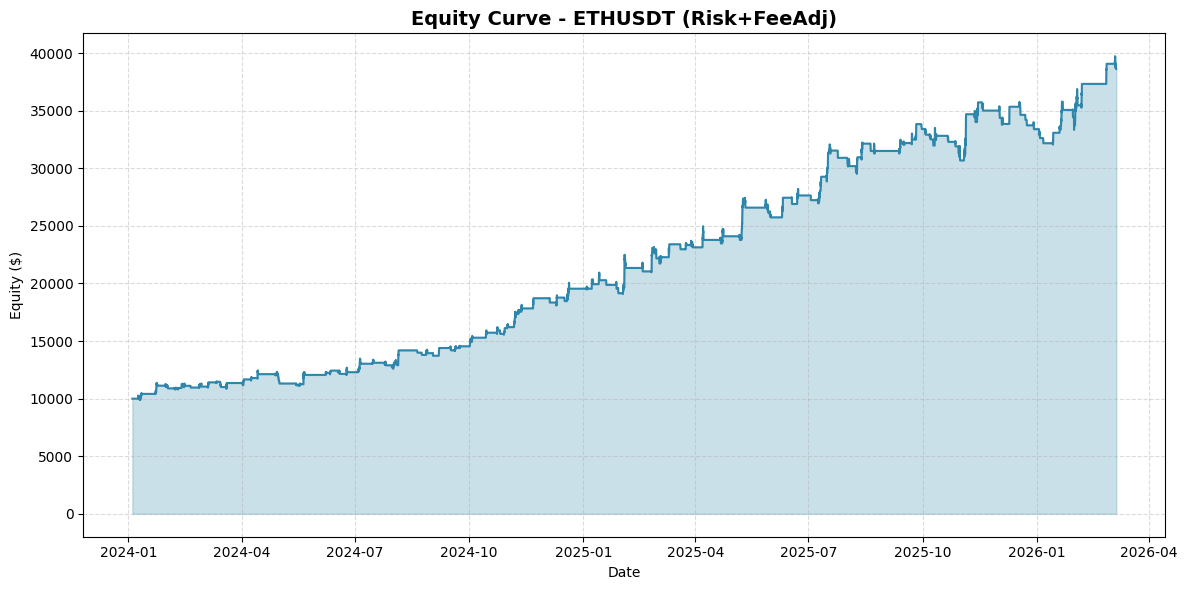


📊 Long vs Short Distribution:
Type
SHORT    109
LONG      84
Name: count, dtype: int64

📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate   Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                          
LONG           84.0  47.0    37.0   55.9524  164.7399    25410.2408  11572.0900         2.1958
SHORT         109.0  50.0    59.0   45.8716  135.6722    37157.4754  22369.2015         1.6611

📊 Sample Trades (first 10):
            Exit Time   Type          Entry Time        Entry         Exit       Qty           SL           TP   Gross PnL  Entry Fee  Exit Fee         PnL       Reason       Capital  Bars Held
0 2024-01-09 09:00:00   LONG 2024-01-08 17:00:00  2293.477030  2291.370000  4.360192  2261.295655  2378.378002   -9.187055   5.000000  4.995406  -19.182461    Time Exit   9980.817539         16
1 2024-01-10 16:00:00   LONG 2024-01-10 00:00:00  2372.357144  2407.150000 

C:\Users\User\AppData\Local\Temp\ipykernel_20896\1874884134.py:552: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby("Type", sort=False).apply(_calc)


In [ ]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break
            data = r.json()
            if not data:
                break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS (V1 structure + EMA200 + Vol filter stats)
# =========================================================
def calculate_indicators(df: pd.DataFrame, lookback: int = 20, ema_len: int = 200, vol_median_win: int = 50):
    data = df.copy()

    # True Range
    data["prev_close"] = data["Close"].shift(1)
    h_l = data["High"] - data["Low"]
    h_pc = (data["High"] - data["prev_close"]).abs()
    l_pc = (data["Low"] - data["prev_close"]).abs()
    data["TR"] = pd.concat([h_l, h_pc, l_pc], axis=1).max(axis=1)

    def atr_ewm(tr, period):
        return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = atr_ewm(data["TR"], 20)
    data["ATR_25"] = atr_ewm(data["TR"], 25)
    data["ATR_30"] = atr_ewm(data["TR"], 30)

    # V1 levels (Highest/Lowest Close)
    data[f"Highest_Close_{lookback}"] = data["Close"].rolling(lookback).max()
    data[f"Lowest_Close_{lookback}"] = data["Close"].rolling(lookback).min()

    # Trend filter
    data[f"EMA_{ema_len}"] = data["Close"].ewm(span=ema_len, adjust=False).mean()

    # Vol filter stats
    data[f"ATR30_MED_{vol_median_win}"] = data["ATR_30"].rolling(vol_median_win).median()
    data["ATR20_PCT"] = data["ATR_20"] / data["Close"]

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER (Pending breakout + Trend/Vol filter + Fee)
#    + Risk-based sizing (qty) with FEE-IN-RISK-BUDGET
# =========================================================
class ATRVolatilityBreakoutRiskBacktester:
    def __init__(self, df: pd.DataFrame, initial_capital: float = 10000.0):
        self.df = df
        self.initial_capital = float(initial_capital)
        self.cash = float(initial_capital)  # realized cash
        self.equity_curve = []
        self.trades = []

        # ---- COSTS ----
        self.fee_rate = 0.0004          # fee / side (0.04%)
        self.slippage_bps = 0.0         # optional; default 0 (set 2-5 bps to stress test)

        # ---- FILTERS ----
        self.lookback = 20
        self.use_trend_filter = True
        self.ema_len = 200
        self.ema_col = f"EMA_{self.ema_len}"

        self.use_vol_median_filter = True
        self.vol_median_win = 50
        self.atr30_med_col = f"ATR30_MED_{self.vol_median_win}"
        self.use_atr_pct_filter = False
        self.min_atr20_pct = 0.0  # e.g. 0.004

        # ---- RISK SIZING ----
        self.risk_per_trade = 0.01       # 1% equity risk / trade (fee-adjusted)
        self.max_notional_pct = 1.0      # cap notional <= equity * max_notional_pct

        # ---- PARAMS tách LONG/SHORT ----
        self.entry_factor_long = 2.4
        self.entry_factor_short = 2.4

        self.sl_factor_long = 1.6
        self.tp_factor_long = 4.4
        self.sl_factor_short = 1.6
        self.tp_factor_short = 4.4

        self.order_expiry_bars_long = 8
        self.order_expiry_bars_short = 8

        self.time_exit_bars_long = 18
        self.time_exit_bars_short = 18

        # ---- STATE ----
        self.position = 0  # 0 flat, 1 long, -1 short
        self.qty = 0.0
        self.entry_price = 0.0
        self.entry_time = None
        self.bars_held = 0
        self.sl = 0.0
        self.tp = 0.0

        self.entry_fee = 0.0

        self.pending_long = None   # {'price':..., 'created_idx':...}
        self.pending_short = None

    # ---------------- helpers ----------------
    def _bps_mult(self, bps: float) -> float:
        return 1.0 + (bps / 10000.0)

    def _apply_slippage(self, side: str, price: float) -> float:
        """
        side:
          - 'buy'  -> pay worse (higher)
          - 'sell' -> receive worse (lower)
        """
        if self.slippage_bps <= 0:
            return price
        m = self._bps_mult(self.slippage_bps)
        return price * m if side == "buy" else price / m

    def _equity(self, close_price: float) -> float:
        if self.position == 0:
            return self.cash
        if self.position == 1:
            return self.cash + (close_price - self.entry_price) * self.qty
        return self.cash + (self.entry_price - close_price) * self.qty

    def _pay_fee(self, notional: float) -> float:
        fee = self.fee_rate * abs(notional)
        self.cash -= fee
        return fee

    def _vol_ok(self, i: int) -> bool:
        # base: ATR30 rising (i-2 > i-3)
        atr30_prev2 = float(self.df.iloc[i-2]["ATR_30"])
        atr30_prev3 = float(self.df.iloc[i-3]["ATR_30"])
        vol_ok = (atr30_prev2 > atr30_prev3)

        if self.use_vol_median_filter:
            atr30_med = float(self.df.iloc[i-2][self.atr30_med_col])
            vol_ok = vol_ok and (atr30_prev2 > atr30_med)

        if self.use_atr_pct_filter:
            atr20_pct = float(self.df.iloc[i-2]["ATR20_PCT"])
            vol_ok = vol_ok and (atr20_pct >= self.min_atr20_pct)

        return bool(vol_ok)

    def _trend_bias(self, i: int) -> str:
        """
        Return 'LONG' or 'SHORT' based on EMA trend.
        Use i-1 to avoid lookahead.
        """
        close_val = float(self.df.iloc[i-1]["Close"])
        ema_val = float(self.df.iloc[i-1][self.ema_col])
        return "LONG" if close_val >= ema_val else "SHORT"

    def _build_triggers(self, i: int):
        ref_atr = float(self.df.iloc[i-3]["ATR_20"])
        hi = float(self.df.iloc[i-2][f"Highest_Close_{self.lookback}"])
        lo = float(self.df.iloc[i-2][f"Lowest_Close_{self.lookback}"])
        long_trigger = hi + self.entry_factor_long * ref_atr
        short_trigger = lo - self.entry_factor_short * ref_atr
        return long_trigger, short_trigger

    def _compute_sl_tp(self, pos_type: int, entry_price: float, bar_idx: int):
        atr20 = float(self.df.iloc[bar_idx]["ATR_20"])
        atr25 = float(self.df.iloc[bar_idx]["ATR_25"])

        if pos_type == 1:
            sl = entry_price - self.sl_factor_long * atr20
            tp = entry_price + self.tp_factor_long * atr25
        else:
            sl = entry_price + self.sl_factor_short * atr20
            tp = entry_price - self.tp_factor_short * atr25
        return sl, tp

    def _size_qty_fee_adjusted(self, entry_fill: float, sl_price: float, close_price: float, pos_type: int) -> float:
        """
        Sizing theo risk_per_trade nhưng tính phí vào/ra trong risk budget:

        Risk ≈ qty * ( |entry - sl_fill| + fee_rate*(entry + sl_fill) )

        - entry dùng entry_fill (sau slippage entry nếu có)
        - sl_fill dùng worst-case fill tại SL (có slippage exit nếu bạn bật)
        """
        eq = self._equity(close_price)
        risk_amt = eq * self.risk_per_trade
        if risk_amt <= 0:
            return 0.0

        # worst-case SL fill with slippage on exit:
        if self.slippage_bps > 0:
            # long exit is sell (worse = lower), short exit is buy (worse = higher)
            sl_fill = self._apply_slippage("sell" if pos_type == 1 else "buy", sl_price)
        else:
            sl_fill = sl_price

        sl_dist = abs(entry_fill - sl_fill)
        risk_per_unit = sl_dist + self.fee_rate * (entry_fill + sl_fill)

        if risk_per_unit <= 0:
            return 0.0

        qty = risk_amt / risk_per_unit

        # cap notional
        max_notional = max(eq * self.max_notional_pct, 0.0)
        if max_notional > 0:
            notional = qty * entry_fill
            if notional > max_notional:
                qty = max_notional / entry_fill

        return max(qty, 0.0)

    # ---------------- main loop ----------------
    def run(self):
        idxs = self.df.index

        for i in range(4, len(self.df)):
            idx = idxs[i]
            bar = self.df.iloc[i]
            high = float(bar["High"])
            low = float(bar["Low"])
            close = float(bar["Close"])

            # A) Manage open position
            if self.position != 0:
                self.bars_held += 1

                exit_happened = False
                exit_price = 0.0
                reason = ""

                if self.position == 1:
                    if low <= self.sl:
                        exit_happened, exit_price, reason = True, self.sl, "Stop Loss"
                    elif high >= self.tp:
                        exit_happened, exit_price, reason = True, self.tp, "Take Profit"
                    elif self.bars_held >= self.time_exit_bars_long:
                        exit_happened, exit_price, reason = True, close, "Time Exit"
                else:
                    if high >= self.sl:
                        exit_happened, exit_price, reason = True, self.sl, "Stop Loss"
                    elif low <= self.tp:
                        exit_happened, exit_price, reason = True, self.tp, "Take Profit"
                    elif self.bars_held >= self.time_exit_bars_short:
                        exit_happened, exit_price, reason = True, close, "Time Exit"

                if exit_happened:
                    self._close_position(exit_price, idx, reason)
                    self.equity_curve.append({"time": idx, "equity": self._equity(close)})
                    continue

            # B) Pending management (only when flat)
            if self.position == 0:
                # pending long
                if self.pending_long is not None:
                    age = i - self.pending_long["created_idx"]
                    if age <= self.order_expiry_bars_long:
                        trig = float(self.pending_long["price"])
                        if high >= trig:
                            self._open_position(1, trig, i, idx)
                            self.pending_long = None
                            self.pending_short = None
                            self.equity_curve.append({"time": idx, "equity": self._equity(close)})
                            continue
                    else:
                        self.pending_long = None

                # pending short
                if self.pending_short is not None:
                    age = i - self.pending_short["created_idx"]
                    if age <= self.order_expiry_bars_short:
                        trig = float(self.pending_short["price"])
                        if low <= trig:
                            self._open_position(-1, trig, i, idx)
                            self.pending_short = None
                            self.pending_long = None
                            self.equity_curve.append({"time": idx, "equity": self._equity(close)})
                            continue
                    else:
                        self.pending_short = None

                # C) Create new pending if none
                if self.pending_long is None and self.pending_short is None and i >= 3:
                    if self._vol_ok(i):
                        long_trigger, short_trigger = self._build_triggers(i)

                        if self.use_trend_filter:
                            bias = self._trend_bias(i)
                            if bias == "LONG":
                                self.pending_long = {"price": long_trigger, "created_idx": i}
                                self.pending_short = None
                            else:
                                self.pending_short = {"price": short_trigger, "created_idx": i}
                                self.pending_long = None
                        else:
                            self.pending_long = {"price": long_trigger, "created_idx": i}
                            self.pending_short = {"price": short_trigger, "created_idx": i}

            # D) Equity end of bar
            self.equity_curve.append({"time": idx, "equity": self._equity(close)})

    # ---------------- execution ----------------
    def _open_position(self, pos_type: int, trigger_price: float, bar_idx: int, time_idx):
        """
        Entry fill:
          - LONG: buy (apply slippage on buy)
          - SHORT: sell (apply slippage on sell)
        Then compute SL/TP, size qty with fee-adjusted risk formula, pay entry fee.
        """
        entry_fill = self._apply_slippage("buy" if pos_type == 1 else "sell", trigger_price)
        sl, tp = self._compute_sl_tp(pos_type, entry_fill, bar_idx)

        close_price = float(self.df.iloc[bar_idx]["Close"])
        qty = self._size_qty_fee_adjusted(entry_fill, sl, close_price, pos_type)
        if qty <= 0:
            return

        # pay entry fee
        entry_notional = qty * entry_fill
        entry_fee = self._pay_fee(entry_notional)

        # set state
        self.position = pos_type
        self.qty = qty
        self.entry_price = entry_fill
        self.entry_time = time_idx
        self.bars_held = 0
        self.sl = sl
        self.tp = tp
        self.entry_fee = entry_fee

    def _close_position(self, raw_exit_price: float, time_idx, reason: str):
        """
        Exit fill:
          - LONG exits by sell (slippage sell)
          - SHORT exits by buy (slippage buy)
        Pay exit fee on notional, realize gross pnl, record net pnl (incl both fees).
        """
        if self.position == 0 or self.qty <= 0:
            return

        exit_fill = self._apply_slippage("sell" if self.position == 1 else "buy", float(raw_exit_price))

        # gross pnl
        if self.position == 1:
            gross_pnl = (exit_fill - self.entry_price) * self.qty
            side = "LONG"
        else:
            gross_pnl = (self.entry_price - exit_fill) * self.qty
            side = "SHORT"

        # pay exit fee
        exit_notional = self.qty * exit_fill
        exit_fee = self._pay_fee(exit_notional)

        # realize pnl into cash (fees already subtracted)
        self.cash += gross_pnl

        net_pnl = gross_pnl - self.entry_fee - exit_fee

        self.trades.append({
            "Exit Time": time_idx,
            "Type": side,
            "Entry Time": self.entry_time,
            "Entry": self.entry_price,
            "Exit": exit_fill,
            "Qty": self.qty,
            "SL": self.sl,
            "TP": self.tp,
            "Gross PnL": gross_pnl,
            "Entry Fee": self.entry_fee,
            "Exit Fee": exit_fee,
            "PnL": net_pnl,
            "Reason": reason,
            "Capital": self.cash,
            "Bars Held": self.bars_held
        })

        # reset
        self.position = 0
        self.qty = 0.0
        self.entry_price = 0.0
        self.entry_time = None
        self.bars_held = 0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_fee = 0.0

# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_advanced_metrics(trades_df, equity_data, initial_capital):
    eq_df = pd.DataFrame(equity_data).copy()
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_capital) / initial_capital

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_capital) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    wins = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = wins / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum()) if total_trades > 0 else 0.0
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df,
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "=" * 70)
    print("METRICS (Risk sizing + fee-in-risk + Trend/Vol filter + Fee)")
    print("=" * 70)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5, color="#2E86AB")
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.25, color="#2E86AB")
    plt.title(f"Equity Curve - {symbol} (Risk+FeeAdj)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.45)
    plt.tight_layout()
    plt.show()

def side_metrics_table(trades_df: pd.DataFrame) -> pd.DataFrame:
    if trades_df is None or trades_df.empty:
        return pd.DataFrame(columns=[
            "Total_Trades","Wins","Losses","Win_Rate","Avg_PnL","Gross_Profit","Gross_Loss","Profit_Factor"
        ])

    df = trades_df.copy()
    df["Type"] = df["Type"].astype(str).str.upper().str.strip()
    df["PnL"] = pd.to_numeric(df["PnL"], errors="coerce")
    df = df.dropna(subset=["Type", "PnL"])
    df = df[df["Type"].isin(["LONG", "SHORT"])]

    def _calc(g: pd.DataFrame) -> pd.Series:
        total = len(g)
        wins = int((g["PnL"] > 0).sum())
        losses = int((g["PnL"] < 0).sum())
        win_rate = (wins / total * 100.0) if total > 0 else 0.0
        avg_pnl = g["PnL"].mean() if total > 0 else 0.0
        gross_profit = g.loc[g["PnL"] > 0, "PnL"].sum()
        gross_loss = abs(g.loc[g["PnL"] < 0, "PnL"].sum())
        profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else np.inf
        return pd.Series({
            "Total_Trades": total,
            "Wins": wins,
            "Losses": losses,
            "Win_Rate": win_rate,
            "Avg_PnL": avg_pnl,
            "Gross_Profit": gross_profit,
            "Gross_Loss": gross_loss,
            "Profit_Factor": profit_factor
        })

    out = df.groupby("Type", sort=False).apply(_calc)
    out["Win_Rate"] = out["Win_Rate"].astype(float).round(4)
    out["Avg_PnL"] = out["Avg_PnL"].astype(float).round(4)
    out["Gross_Profit"] = out["Gross_Profit"].astype(float).round(4)
    out["Gross_Loss"] = out["Gross_Loss"].astype(float).round(4)
    out["Profit_Factor"] = out["Profit_Factor"].astype(float).replace([np.inf], np.nan).round(4)
    return out

# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "30/05/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if len(df_raw) <= 500:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    df_calc = calculate_indicators(df_raw, lookback=20, ema_len=200, vol_median_win=50)

    bt = ATRVolatilityBreakoutRiskBacktester(df_calc, initial_capital=10000)

    # ====== COSTS ======
    bt.fee_rate = 0.0005
    bt.slippage_bps = 0.0  # set 2.0 để stress test

    # ====== FILTERS ======
    bt.use_trend_filter = True
    bt.use_vol_median_filter = True
    bt.use_atr_pct_filter = False
    bt.min_atr20_pct = 0.004  # hiệu lực khi use_atr_pct_filter=True

    # ====== RISK ======
    bt.risk_per_trade = 0.02
    bt.max_notional_pct = 1.0

    # ====== SPLIT PARAMS LONG/SHORT (tuỳ chỉnh) ======
    bt.entry_factor_long = 2.6
    bt.entry_factor_short = 2.4
    bt.sl_factor_long = 1.6
    bt.tp_factor_long = 4.4
    bt.sl_factor_short = 1.6
    bt.tp_factor_short = 4.4
    bt.order_expiry_bars_long = 10
    bt.order_expiry_bars_short = 10
    bt.time_exit_bars_long = 16
    bt.time_exit_bars_short = 20

    print("🚀 Running backtest (risk sizing fee-adjusted)...")
    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ Không có lệnh nào được thực hiện.")
        raise SystemExit

    metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_capital)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Long vs Short Distribution:")
    print(trades_df["Type"].value_counts())

    print("\n📊 Winrate theo từng phía (Long/Short):")
    print(side_metrics_table(trades_df).to_string())

    print("\n📊 Sample Trades (first 10):")
    print(trades_df.head(10).to_string())